# Preparação de Dados — Risco de Tuberculose nos Municípios do Paraná

Alunas: Julia Yokoyama Massaki e Sofia Gutschow Casal

**Tarefa preditiva:** classificar, para cada município do Paraná, a **categoria de risco de tuberculose no ano seguinte** (Baixo/Sem casos, Moderado, Alto), a partir de indicadores socioeconômicos, demográficos e climáticos do ano corrente.

Este notebook cobre o pipeline completo exigido pelo trabalho:

1. Integração de múltiplas fontes de dados (já consolidadas em um Data Warehouse Oracle - view_municipio_tb)
2. Definição da tarefa preditiva e construção da variável alvo
3. Engenharia de features derivadas
4. Injeção controlada de ruído/erros (documentada) e limpeza de dados
5. Codificação de variáveis categóricas
6. Treinamento, validação cruzada (GroupKFold), tuning de hiperparâmetros e seleção de features
7. Comparação de acurácia (balanced accuracy) antes e depois da inclusão das features derivadas
8. Avaliação final (matriz de confusão) e persistência do modelo

## 1. Integração de dados

Os dados usados aqui já são o resultado da integração de múltiplas fontes originais, feita anteriormente em um Data Warehouse (Oracle, esquema estrela) desenvolvido em trabalho prévio da disciplina de Banco de Dados:

- **Casos de tuberculose** por município/ano (SESA/DATASUS)
- **PIB e PIB per capita** por município/ano (IBGE/IPARDES)
- **Densidade demográfica** (IBGE)
- **Variáveis climáticas** — temperatura, umidade, precipitação, dias de chuva (INMET, por estação de referência)
- **Indicador de pandemia** (COVID-19, S/N por ano)

A view `vw_municipio_tb` consolida essas fontes em uma tabela, uma linha por (município, ano). É esse resultado da integração que carregamos abaixo


In [64]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
import joblib
import json

pd.set_option("display.max_columns", 20)

RAW_PATH = "dados/vw_municipio_tb.csv"

df_raw = pd.read_csv(RAW_PATH)
df_raw.columns = [c.strip().lower() for c in df_raw.columns]
print("Shape:", df_raw.shape)
print("Municípios distintos:", df_raw["cd_ibge"].nunique())
print("Anos:", sorted(df_raw["ano"].unique()))
df_raw.head()

Shape: (1668, 16)
Municípios distintos: 285
Anos: [np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]


,cd_ibge,nm_municipio,nm_regiao,ano,pandemia,casos_tb,pib_per_capita,pib_total,dens_demografica,temp_max_anual,temp_min_anual,temp_med_anual,umidade_med_anual,precipitacao_total,dias_chuva,estacao_referencia
0,410010,ABATIA,RGI de Santo Antônio da Platina,2023,N,2,41039,297166,32.04,36.1,4.2,25.17,67.52,465.2,63,JOAQUIM TAVORA
1,410010,ABATIA,RGI de Santo Antônio da Platina,2018,N,0,21529,161620,32.93,35.9,1.9,21.47,72.22,854.6,108,JOAQUIM TAVORA
2,410010,ABATIA,RGI de Santo Antônio da Platina,2019,N,2,25296,188631,32.71,39.0,-0.2,22.36,70.42,933.6,110,JOAQUIM TAVORA
3,410010,ABATIA,RGI de Santo Antônio da Platina,2020,S,0,32358,239709,32.50,39.2,2.6,22.43,66.29,805.4,96,JOAQUIM TAVORA
4,410010,ABATIA,RGI de Santo Antônio da Platina,2021,S,1,30138,221817,32.29,37.0,-2.0,23.00,63.12,768.0,100,JOAQUIM TAVORA


In [65]:
# Panorama de faltantes ja existentes nos dados originais (antes de acrescentarmos ruido)
df_raw.isna().sum().to_frame("faltantes_originais").query("faltantes_originais > 0")

,faltantes_originais
temp_max_anual,54
temp_min_anual,54
temp_med_anual,54
umidade_med_anual,54


Os dados originais já apresentam **54 valores faltantes reais** nas variáveis climáticas (falhas de estação). Mesmo assim, injetamos ruído artificial adicional e documentado, incluindo valores impossíveis (outliers fora de faixa).

## 2. Definição da tarefa preditiva e variável alvo

**Tarefa:** classificação multiclasse. Para cada município e ano, prever a **categoria de risco de TB no ano seguinte**, com base nos casos absolutos de TB:

- `Baixo/Sem casos`: até 5 casos
- `Moderado`: 6 a 20 casos
- `Alto`: mais de 20 casos

A variável alvo (`target_categoria_risco_ano_seguinte`) é obtida deslocando a categoria de risco do próprio município em um ano — ou seja, o modelo aprende a prever o futuro a partir do presente.


In [66]:
def categoria_risco(casos_tb: float) -> str:
    if pd.isna(casos_tb):
        return np.nan
    if casos_tb <= 5:
        return "Baixo/Sem casos"
    if 6 <= casos_tb <= 20:
        return "Moderado"
    return "Alto"

df = df_raw.dropna(subset=["ano"]).copy()
df["ano"] = df["ano"].astype(int)
df = df.sort_values(["cd_ibge", "ano"]).reset_index(drop=True)

df["categoria_risco"] = df["casos_tb"].apply(categoria_risco)
df["target_categoria_risco_ano_seguinte"] = df.groupby("cd_ibge")["categoria_risco"].shift(-1)

print("Distribuição da categoria de risco (ano corrente):")
print(df["categoria_risco"].value_counts())


Distribuição da categoria de risco (ano corrente):
categoria_risco
Baixo/Sem casos    1326
Moderado            214
Alto                128
Name: count, dtype: int64


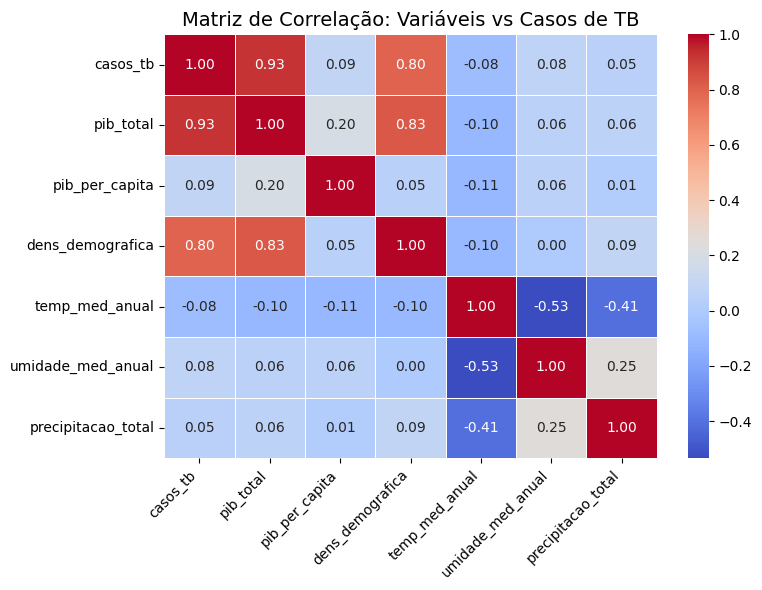

In [67]:
# Selecionar apenas colunas numéricas para a correlação
colunas_num = ["casos_tb", "pib_total", "pib_per_capita", "dens_demografica", 
               "temp_med_anual", "umidade_med_anual", "precipitacao_total"]

correlacoes = df[colunas_num].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(correlacoes, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, ax=ax)
ax.set_title("Matriz de Correlação: Variáveis vs Casos de TB", fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 3. Engenharia de features derivadas

Além das variáveis originais, construímos quatro features derivadas que agregam informação temporal e de interação, hipoteticamente mais informativas para prever o *próximo* ano do que os valores brutos do ano corrente isoladamente:

- `casos_tb_ano_anterior`: casos de TB do município no ano anterior (memória de curto prazo)
- `casos_tb_media_2anos`: média móvel de 2 anos dos casos de TB (suaviza ruído ano a ano)
- `interacao_casos_densidade`: interação entre casos de TB e densidade demográfica (contágio por área)
- `pib_per_capita_var_pct`: variação percentual do PIB per capita em relação ao ano anterior (choque econômico)


In [68]:
df["casos_tb_ano_anterior"] = df.groupby("cd_ibge")["casos_tb"].shift(1)

df["casos_tb_media_2anos"] = df.groupby("cd_ibge")["casos_tb"].transform(
    lambda x: x.rolling(2, min_periods=1).mean()
)

df["interacao_casos_densidade"] = df["casos_tb"] * df["dens_demografica"]

df["pib_per_capita_var_pct"] = df.groupby("cd_ibge")["pib_per_capita"].pct_change() * 100

# Só ficam no dataset final as instâncias em que sabemos o alvo (ano seguinte existe)
df_instancias = df.dropna(subset=["target_categoria_risco_ano_seguinte"]).copy()
print(f"Linhas no dataset final de instâncias: {len(df_instancias)}")
print(df_instancias["target_categoria_risco_ano_seguinte"].value_counts())

df_instancias.to_csv("dados/dataset_instancias.csv", index=False)

Linhas no dataset final de instâncias: 1383
target_categoria_risco_ano_seguinte
Baixo/Sem casos    1105
Moderado            169
Alto                109
Name: count, dtype: int64


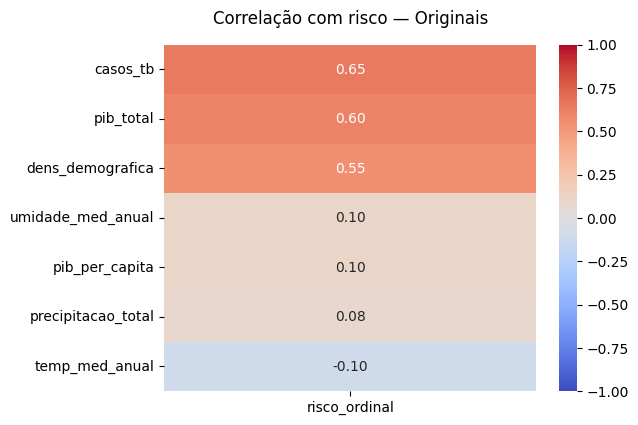


--- Correlação com risco — Originais ---
Mais correlacionadas positivamente (aumentam o risco):
                  risco_ordinal
casos_tb               0.646199
pib_total              0.601924
dens_demografica       0.550651

Mais correlacionadas negativamente (diminuem o risco):
                    risco_ordinal
pib_per_capita           0.103061
precipitacao_total       0.078740
temp_med_anual          -0.097922 



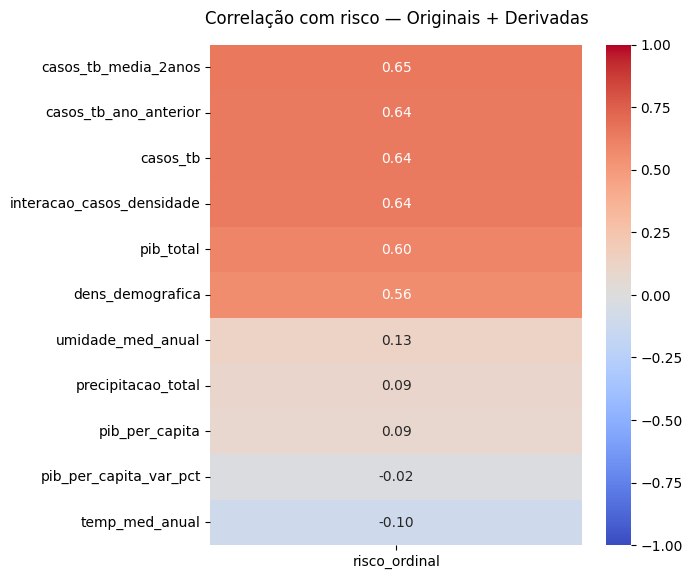


--- Correlação com risco — Originais + Derivadas ---
Mais correlacionadas positivamente (aumentam o risco):
                       risco_ordinal
casos_tb_media_2anos        0.652950
casos_tb_ano_anterior       0.643116
casos_tb                    0.641112

Mais correlacionadas negativamente (diminuem o risco):
                        risco_ordinal
pib_per_capita               0.085511
pib_per_capita_var_pct      -0.019450
temp_med_anual              -0.101815 



In [69]:
import matplotlib.pyplot as plt
import seaborn as sns

ordem_risco = {"Baixo/Sem casos": 0, "Moderado": 1, "Alto": 2}
df_instancias["risco_ordinal"] = df_instancias["target_categoria_risco_ano_seguinte"].map(ordem_risco)

colunas_num = [
    "casos_tb", "pib_total", "pib_per_capita", "dens_demografica", 
    "temp_med_anual", "umidade_med_anual", "precipitacao_total"
]

colunas_num_v2 = colunas_num + [
    "casos_tb_ano_anterior", 
    "casos_tb_media_2anos", 
    "pib_per_capita_var_pct", 
    "interacao_casos_densidade"
]

def plot_correlacao_com_target(colunas, titulo):
    dados = df_instancias[colunas + ["risco_ordinal"]].dropna()
    
    corr = dados.corr(method="spearman")[["risco_ordinal"]].sort_values(by="risco_ordinal", ascending=False)
    corr = corr.drop("risco_ordinal")  # remove a correlação dele com ele mesmo (que é 1.0)

    plt.figure(figsize=(6, len(colunas) * 0.5 + 1))
    sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
    plt.title(titulo, pad=15)
    plt.show()

    print(f"\n--- {titulo} ---")
    print("Mais correlacionadas positivamente (aumentam o risco):")
    print(corr.head(3).to_string())
    print("\nMais correlacionadas negativamente (diminuem o risco):")
    print(corr.tail(3).to_string(), "\n")

plot_correlacao_com_target(colunas_num, "Correlação com risco — Originais")
plot_correlacao_com_target(colunas_num_v2, "Correlação com risco — Originais + Derivadas")

## 4. Injeção controlada de ruído/erros (documentada)

Injetamos artificialmente ruído em ~6% das células de cinco colunas numéricas (metade vira **faltante**, metade vira **outlier** fora da faixa plausível) e erros de digitação em ~3% da coluna categórica `nm_regiao`. Todo ruído injetado é logado para auditoria (antes/depois)


In [70]:
RNG = np.random.default_rng(0)

COLUNAS_NUMERICAS_PARA_RUIDO = [
    "dens_demografica", "pib_per_capita", "temp_med_anual",
    "umidade_med_anual", "precipitacao_total",
]

FAIXAS_VALIDAS = {
    "dens_demografica": (0, 15000),
    "pib_per_capita": (0, 300000),
    "temp_med_anual": (-5, 40),
    "umidade_med_anual": (0, 100),
    "precipitacao_total": (0, 4000),
}

def injetar_ruido(df_in, frac=0.06):
    df_out = df_in.copy()
    log = []
    for col in COLUNAS_NUMERICAS_PARA_RUIDO:
        n = len(df_out)
        n_ruido = max(1, int(n * frac))
        idx = RNG.choice(df_out.index, size=n_ruido, replace=False)
        for i in idx:
            valor_original = df_out.at[i, col]
            if RNG.random() < 0.5:
                df_out.at[i, col] = np.nan
                tipo = "faltante"
            else:
                fator = RNG.choice([-1, 10, 50])
                df_out.at[i, col] = valor_original * fator
                tipo = "outlier"
            log.append({"linha": i, "coluna": col, "valor_original": valor_original,
                         "valor_ruidoso": df_out.at[i, col], "tipo_ruido": tipo})

    n_typo = max(1, int(len(df_out) * 0.03))
    idx_typo = RNG.choice(df_out.index, size=n_typo, replace=False)
    for i in idx_typo:
        original = df_out.at[i, "nm_regiao"]
        if isinstance(original, str):
            variante = RNG.choice([original.upper(), original.lower() + "  ", " " + original])
            df_out.at[i, "nm_regiao"] = variante
            log.append({"linha": i, "coluna": "nm_regiao", "valor_original": original,
                         "valor_ruidoso": variante, "tipo_ruido": "inconsistencia_texto"})

    log_df = pd.DataFrame(log)
    log_df.to_csv("dados/log_ruido_injetado.csv", index=False)
    print(f"Ruído injetado em {len(log_df)} células.")
    return df_out, log_df

df_ruido, log_ruido = injetar_ruido(df_instancias)
df_ruido.to_csv("dados/dataset_com_ruido.csv", index=False)
log_ruido["tipo_ruido"].value_counts()


Ruído injetado em 451 células.


tipo_ruido
outlier                 225
faltante                185
inconsistencia_texto     41
Name: count, dtype: int64

In [71]:
log_ruido.head(10)

,linha,coluna,valor_original,valor_ruidoso,tipo_ruido
0,282,dens_demografica,45.93,459.3,outlier
1,418,dens_demografica,9.86,-9.86,outlier
2,1194,dens_demografica,23.12,231.2,outlier
3,120,dens_demografica,38.08,1904.0,outlier
4,221,dens_demografica,57.91,NaN,faltante
5,962,dens_demografica,22.51,1125.5,outlier
6,35,dens_demografica,26.45,1322.5,outlier
7,1477,dens_demografica,11.92,NaN,faltante
8,1397,dens_demografica,11.75,587.5,outlier
9,1159,dens_demografica,131.52,6576.0,outlier


## 5. Detecção e correção de erros (faixas plausíveis)

Valores fora de faixas plausíveis definidas por conhecimento de domínio (ex.: densidade demográfica negativa ou acima de 15.000 hab/km², umidade fora de 0–100%) são marcados como erro e tratados como faltante — entrando no mesmo fluxo de imputação da próxima etapa.


In [72]:
def detectar_e_corrigir_erros(df_in):
    df_out = df_in.copy()
    for col, (lo, hi) in FAIXAS_VALIDAS.items():
        fora_da_faixa = ~df_out[col].between(lo, hi) & df_out[col].notna()
        n = fora_da_faixa.sum()
        if n:
            print(f"  {col}: {n} valores fora da faixa [{lo}, {hi}] -> marcados como erro (NaN)")
        df_out.loc[fora_da_faixa, col] = np.nan
    return df_out

df_ok = detectar_e_corrigir_erros(df_ruido)

  dens_demografica: 15 valores fora da faixa [0, 15000] -> marcados como erro (NaN)
  pib_per_capita: 43 valores fora da faixa [0, 300000] -> marcados como erro (NaN)
  temp_med_anual: 43 valores fora da faixa [-5, 40] -> marcados como erro (NaN)
  umidade_med_anual: 38 valores fora da faixa [0, 100] -> marcados como erro (NaN)
  precipitacao_total: 42 valores fora da faixa [0, 4000] -> marcados como erro (NaN)


## 6. Padronização de texto e imputação de faltantes

- `nm_regiao`: strip + title case, eliminando inconsistências de digitação/capitalização
- Variáveis numéricas: imputação por mediana dentro da região, com *fallback* para mediana global se a região inteira ficar sem valor


In [73]:
def padronizar_texto(df_in):
    df_out = df_in.copy()
    df_out["nm_regiao"] = df_out["nm_regiao"].str.strip().str.title()
    return df_out

def imputar_faltantes(df_in):
    df_out = df_in.copy()
    colunas_numericas = COLUNAS_NUMERICAS_PARA_RUIDO + [
        "casos_tb_ano_anterior", "pib_per_capita_var_pct", "dias_chuva",
        "temp_max_anual", "temp_min_anual",
    ]
    for col in colunas_numericas:
        if col not in df_out.columns:
            continue
        antes = df_out[col].isna().sum()
        df_out[col] = df_out.groupby("nm_regiao")[col].transform(lambda s: s.fillna(s.median()))
        df_out[col] = df_out[col].fillna(df_out[col].median())
        depois = df_out[col].isna().sum()
        if antes:
            print(f"  {col}: {antes} faltantes -> {depois} após imputação por mediana regional")
    return df_out

df_ok = padronizar_texto(df_ok)
df_ok = imputar_faltantes(df_ok)
print("\nFaltantes restantes no dataset:", df_ok.isna().sum().sum())

  dens_demografica: 48 faltantes -> 0 após imputação por mediana regional
  pib_per_capita: 77 faltantes -> 0 após imputação por mediana regional
  temp_med_anual: 135 faltantes -> 0 após imputação por mediana regional
  umidade_med_anual: 131 faltantes -> 0 após imputação por mediana regional
  precipitacao_total: 78 faltantes -> 0 após imputação por mediana regional
  casos_tb_ano_anterior: 285 faltantes -> 0 após imputação por mediana regional
  pib_per_capita_var_pct: 285 faltantes -> 0 após imputação por mediana regional
  temp_max_anual: 54 faltantes -> 0 após imputação por mediana regional
  temp_min_anual: 54 faltantes -> 0 após imputação por mediana regional

Faltantes restantes no dataset: 0


## 7. Codificação de variáveis categóricas

- `pandemia` (S/N) → binário `pandemia_flag`
- `nm_regiao` → one-hot encoding (`regiao_*`) — poucas categorias, Random Forest lida bem sem necessidade de ordinalidade


In [74]:
def codificar_categoricas(df_in):
    df_out = df_in.copy()
    df_out["pandemia_flag"] = (df_out["pandemia"].str.upper() == "S").astype(int)
    df_out = pd.get_dummies(df_out, columns=["nm_regiao"], prefix="regiao")
    return df_out

df_limpo = codificar_categoricas(df_ok)
df_limpo.to_csv("dados/dataset_limpo.csv", index=False)
print("Shape final do dataset limpo:", df_limpo.shape)
df_limpo.head()

Shape final do dataset limpo: (1383, 52)


,cd_ibge,nm_municipio,ano,pandemia,casos_tb,pib_per_capita,pib_total,dens_demografica,temp_max_anual,temp_min_anual,...,regiao_Rgi De Paranaguá,regiao_Rgi De Paranavaí,regiao_Rgi De Pato Branco,regiao_Rgi De Pitanga,regiao_Rgi De Ponta Grossa,regiao_Rgi De Santo Antônio Da Platina,regiao_Rgi De Telêmaco Borba,regiao_Rgi De Toledo,regiao_Rgi De Umuarama,regiao_Rgi De União Da Vitória
0,410010,ABATIA,2018,N,0,21529.0,161620,32.93,35.9,1.9,...,False,False,False,False,False,True,False,False,False,False
1,410010,ABATIA,2019,N,2,25296.0,188631,32.71,39.0,-0.2,...,False,False,False,False,False,True,False,False,False,False
2,410010,ABATIA,2020,S,0,32358.0,239709,32.50,39.2,2.6,...,False,False,False,False,False,True,False,False,False,False
3,410010,ABATIA,2021,S,1,30138.0,221817,1614.50,37.0,-2.0,...,False,False,False,False,False,True,False,False,False,False
4,410010,ABATIA,2022,S,0,39014.0,282503,31.76,35.3,1.5,...,False,False,False,False,False,True,False,False,False,False


## 8. Treinamento e avaliação dos modelos

Comparamos dois conjuntos de features:

- **Modelo A (baseline):** apenas variáveis originais (casos de TB do ano corrente, PIB, densidade, clima, flag de pandemia, região)
- **Modelo B (aprimorado):** baseline + as 4 features derivadas (`casos_tb_ano_anterior`, `casos_tb_media_2anos`, `interacao_casos_densidade` e `pib_per_capita_var_pct`)

Usamos **GroupKFold** agrupando por município (`cd_ibge`): o GroupKFold garante que cada município apareça inteiramente em um único fold (Como temos dados do mesmo município ao longo de vários anos, um split normal colocaria Londrina (2018) no treino e Londrina (2019) no teste. O modelo ia decorar a cidade e a acurácia seria ilusória (overfitting))

Para cada modelo: validação cruzada com Random Forest, seguida de **tuning de hiperparâmetros** via `GridSearchCV`.

*Como o algoritmo escolhido foi o Random Forest, não é necessário técnicas de normalização ou padronização (como StandardScaler), porque a divisão de nós nas árvores é invariante à escala das features*

In [75]:
from sklearn.model_selection import GroupKFold, GridSearchCV, cross_val_score, GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix

TARGET = "target_categoria_risco_ano_seguinte"
GRUPO = "cd_ibge"

FEATURES_BASE = [
    "casos_tb", "pib_per_capita", "pib_total", "dens_demografica",
    "temp_max_anual", "temp_min_anual", "temp_med_anual",
    "umidade_med_anual", "precipitacao_total", "dias_chuva",
    "pandemia_flag",
]
FEATURES_DERIVADAS = ["casos_tb_ano_anterior", "pib_per_capita_var_pct",
                       "casos_tb_media_2anos", "interacao_casos_densidade"]

def montar_X_y(df_in, colunas_features):
    colunas_regiao = [c for c in df_in.columns if c.startswith("regiao_")]
    colunas = [c for c in colunas_features if c in df_in.columns] + colunas_regiao
    X = df_in[colunas].copy()
    y = df_in[TARGET].copy()
    groups = df_in[GRUPO].copy()
    return X, y, groups, colunas

def avaliar_modelo(X, y, groups, nome_modelo, n_splits=4):
    le = LabelEncoder()
    y_enc = le.fit_transform(y)
    gkf = GroupKFold(n_splits=n_splits)

    modelo = RandomForestClassifier(random_state = 0, class_weight="balanced")
    scores = cross_val_score(modelo, X, y_enc, groups=groups, cv=gkf, scoring="balanced_accuracy")
    print(f"[{nome_modelo}] Balanced accuracy (CV, sem tuning): {scores.mean():.3f} +/- {scores.std():.3f}")

    param_grid = {
        "n_estimators": [100, 300],
        "max_depth": [None, 10, 15],
        "min_samples_split": [2, 5],
        "min_samples_leaf": [1, 2],
    }
    splits = list(gkf.split(X, y_enc, groups))
    busca = GridSearchCV(
        RandomForestClassifier(random_state = 0, class_weight="balanced"),
        param_grid, cv=splits, scoring="balanced_accuracy", n_jobs=-1,
    )
    busca.fit(X, y_enc)
    print(f"[{nome_modelo}] Melhores hiperparâmetros: {busca.best_params_}")
    print(f"[{nome_modelo}] Melhor balanced accuracy (CV, com tuning): {busca.best_score_:.3f}")

    melhor_modelo = busca.best_estimator_
    importancias = pd.Series(melhor_modelo.feature_importances_, index=X.columns).sort_values(ascending=False)
    print(f"[{nome_modelo}] Top features por importância:")
    print(importancias.head(8).to_string())

    return {"modelo": melhor_modelo, "label_encoder": le,
            "cv_score_sem_tuning": scores.mean(), "cv_score_com_tuning": busca.best_score_,
            "importancias": importancias}


In [76]:
print("MODELO A - BASELINE (sem features derivadas)")
print("-="*70)
X_a, y_a, groups_a, cols_a = montar_X_y(df_limpo, FEATURES_BASE)
resultado_a = avaliar_modelo(X_a, y_a, groups_a, "BASELINE")

MODELO A - BASELINE (sem features derivadas)
-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=
[BASELINE] Balanced accuracy (CV, sem tuning): 0.765 +/- 0.013
[BASELINE] Melhores hiperparâmetros: {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}
[BASELINE] Melhor balanced accuracy (CV, com tuning): 0.821
[BASELINE] Top features por importância:
casos_tb              0.310447
pib_total             0.244145
dens_demografica      0.171373
pib_per_capita        0.045344
umidade_med_anual     0.030330
dias_chuva            0.028260
temp_med_anual        0.027655
precipitacao_total    0.023721


In [77]:
print("MODELO B - APRIMORADO (com features derivadas)")
print("-="*70)
X_b, y_b, groups_b, cols_b = montar_X_y(df_limpo, FEATURES_BASE + FEATURES_DERIVADAS)
resultado_b = avaliar_modelo(X_b, y_b, groups_b, "APRIMORADO")

MODELO B - APRIMORADO (com features derivadas)
-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=
[APRIMORADO] Balanced accuracy (CV, sem tuning): 0.821 +/- 0.025
[APRIMORADO] Melhores hiperparâmetros: {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
[APRIMORADO] Melhor balanced accuracy (CV, com tuning): 0.843
[APRIMORADO] Top features por importância:
casos_tb_media_2anos         0.242539
casos_tb                     0.149580
interacao_casos_densidade    0.148038
pib_total                    0.115228
casos_tb_ano_anterior        0.082300
dens_demografica             0.073485
pib_per_capita               0.025114
pib_per_capita_var_pct       0.021617


## 9. Seleção de features

A partir do Modelo B, ranqueamos as features por importância (Random Forest) e cortamos as pouco informativas (importância < 0.02), mantendo sempre juntas as colunas one-hot de região.


In [78]:
def selecionar_features(X, y, groups, limiar_importancia = 0.02):
    le = LabelEncoder()
    y_enc = le.fit_transform(y)
    modelo = RandomForestClassifier(n_estimators = 300, random_state = 0, class_weight = "balanced")
    modelo.fit(X, y_enc)
    importancias = pd.Series(modelo.feature_importances_, index=X.columns)

    colunas_regiao = [c for c in X.columns if c.startswith("regiao_")]
    colunas_selecionadas = [c for c in X.columns if c in colunas_regiao or importancias[c] >= limiar_importancia]
    print(f"Features cortadas: {[c for c in X.columns if c not in colunas_selecionadas]}")
    print(f"Features mantidas: {colunas_selecionadas}")
    return colunas_selecionadas

colunas_selecionadas = selecionar_features(X_b, y_b, groups_b)
X_c = X_b[colunas_selecionadas]

print("MODELO C - APRIMORADO + SELEÇÃO DE FEATURES")
print("-="*70)
resultado_c = avaliar_modelo(X_c, y_b, groups_b, "SELECIONADO")


Features cortadas: ['temp_max_anual', 'temp_min_anual', 'temp_med_anual', 'precipitacao_total', 'pandemia_flag']
Features mantidas: ['casos_tb', 'pib_per_capita', 'pib_total', 'dens_demografica', 'umidade_med_anual', 'dias_chuva', 'casos_tb_ano_anterior', 'pib_per_capita_var_pct', 'casos_tb_media_2anos', 'interacao_casos_densidade', 'regiao_Rgi De Apucarana', 'regiao_Rgi De Campo Mourão', 'regiao_Rgi De Cascavel', 'regiao_Rgi De Cianorte', 'regiao_Rgi De Cornélio Procópio - Bandeirantes', 'regiao_Rgi De Curitiba', 'regiao_Rgi De Dois Vizinhos', 'regiao_Rgi De Foz Do Iguaçu', 'regiao_Rgi De Francisco Beltrão', 'regiao_Rgi De Guarapuava', 'regiao_Rgi De Ibaiti', 'regiao_Rgi De Irati', 'regiao_Rgi De Ivaiporã', 'regiao_Rgi De Laranjeiras Do Sul - Quedas Do Iguaçu', 'regiao_Rgi De Loanda', 'regiao_Rgi De Londrina', 'regiao_Rgi De Marechal Cândido Rondon', 'regiao_Rgi De Maringá', 'regiao_Rgi De Paranacity - Colorado', 'regiao_Rgi De Paranaguá', 'regiao_Rgi De Paranavaí', 'regiao_Rgi De Pat

## 10. Comparativo final: acurácia antes e depois das features derivadas

                           modelo  balanced_accuracy_cv  ganho_vs_baseline
Baseline (sem features derivadas)              0.820892           0.000000
Aprimorado (+ features derivadas)              0.843129           0.022238
 Aprimorado + seleção de features              0.841154           0.020262

Ganho com as features derivadas: +0.022
Ganho com a seleção de features : -0.002


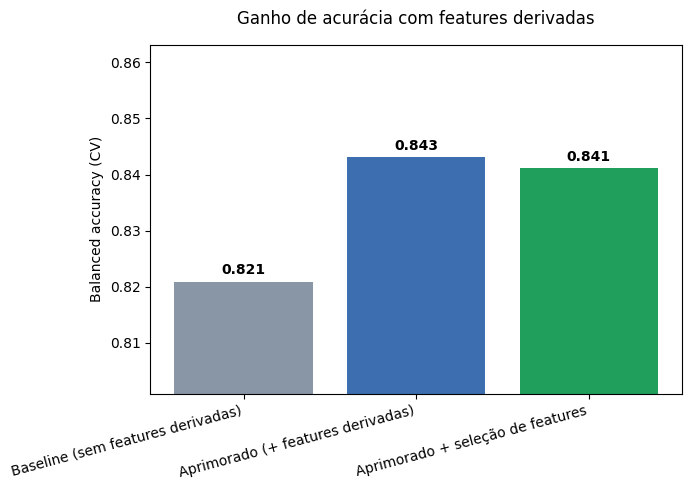

In [79]:
comparativo = pd.DataFrame({
    "modelo": ["Baseline (sem features derivadas)", "Aprimorado (+ features derivadas)", "Aprimorado + seleção de features"],
    "balanced_accuracy_cv": [resultado_a["cv_score_com_tuning"], resultado_b["cv_score_com_tuning"], resultado_c["cv_score_com_tuning"]],
})
comparativo["ganho_vs_baseline"] = comparativo["balanced_accuracy_cv"] - resultado_a["cv_score_com_tuning"]
print(comparativo.to_string(index=False))

ganho_features = resultado_b["cv_score_com_tuning"] - resultado_a["cv_score_com_tuning"]
ganho_selecao = resultado_c["cv_score_com_tuning"] - resultado_b["cv_score_com_tuning"]
print(f"\nGanho com as features derivadas: {ganho_features:+.3f}")
print(f"Ganho com a seleção de features : {ganho_selecao:+.3f}")

fig, ax = plt.subplots(figsize=(7, 5))
barras = ax.bar(comparativo["modelo"], comparativo["balanced_accuracy_cv"], color=["#8896a6", "#3d6fb0", "#1f9e5c"])

ax.set_ylabel("Balanced accuracy (CV)")
ax.set_title("Ganho de acurácia com features derivadas", pad=15)

min_acc = comparativo["balanced_accuracy_cv"].min()
max_acc = comparativo["balanced_accuracy_cv"].max()
ax.set_ylim(min_acc - 0.02, max_acc + 0.02)

ax.bar_label(barras, fmt='%.3f', padding=3, fontweight='bold')

plt.xticks(rotation=15, ha="right")
fig.tight_layout()
plt.show()

## 11. Avaliação final: matriz de confusão e modelo escolhido

Escolhemos o melhor dos três modelos (maior balanced accuracy em CV) e geramos um holdout por município (`GroupShuffleSplit`, 25%) apenas para diagnóstico visual de erro por classe — diferente do CV usado para comparar acurácia. Por fim, o modelo final é reajustado com todos os dados e persistido.


In [80]:
candidatos = {
    "baseline": (resultado_a, X_a),
    "aprimorado": (resultado_b, X_b),
    "selecionado": (resultado_c, X_c),
}
nome_melhor = max(candidatos, key=lambda k: candidatos[k][0]["cv_score_com_tuning"])
melhor_resultado, X_melhor = candidatos[nome_melhor]
print(f"Modelo final escolhido: {nome_melhor} (balanced accuracy CV = {melhor_resultado['cv_score_com_tuning']:.3f})")

melhores_params = {k: v for k, v in melhor_resultado["modelo"].get_params().items()
                    if k in ("n_estimators", "max_depth", "min_samples_leaf", "min_samples_split")}

le_final = LabelEncoder()
y_enc_final = le_final.fit_transform(df_limpo[TARGET])

gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state = 0)
idx_treino, idx_teste = next(gss.split(X_melhor, y_enc_final, df_limpo[GRUPO]))

modelo_holdout = RandomForestClassifier(random_state = 0, class_weight="balanced", **melhores_params)
modelo_holdout.fit(X_melhor.iloc[idx_treino], y_enc_final[idx_treino])
y_pred = modelo_holdout.predict(X_melhor.iloc[idx_teste])

print(f"\nClassification report (holdout por município, 25%) — modelo {nome_melhor}:")
print(classification_report(y_enc_final[idx_teste], y_pred, target_names=le_final.classes_, zero_division=0))

Modelo final escolhido: aprimorado (balanced accuracy CV = 0.843)

Classification report (holdout por município, 25%) — modelo aprimorado:
                 precision    recall  f1-score   support

           Alto       0.75      0.95      0.84        22
Baixo/Sem casos       0.96      0.96      0.96       299
       Moderado       0.28      0.22      0.24        23

       accuracy                           0.91       344
      macro avg       0.66      0.71      0.68       344
   weighted avg       0.90      0.91      0.91       344



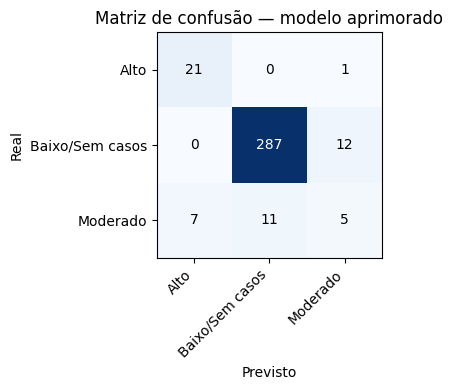

In [81]:
matriz = confusion_matrix(y_enc_final[idx_teste], y_pred, labels=range(len(le_final.classes_)))

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(matriz, cmap="Blues")
ax.set_xticks(range(len(le_final.classes_)))
ax.set_yticks(range(len(le_final.classes_)))
ax.set_xticklabels(le_final.classes_, rotation=45, ha="right")
ax.set_yticklabels(le_final.classes_)
ax.set_xlabel("Previsto")
ax.set_ylabel("Real")
ax.set_title(f"Matriz de confusão — modelo {nome_melhor}")
for i in range(matriz.shape[0]):
    for j in range(matriz.shape[1]):
        ax.text(j, i, matriz[i, j], ha="center", va="center",
                color="white" if matriz[i, j] > matriz.max() / 2 else "black")
fig.tight_layout()
plt.show()

In [82]:
# Reajusta o modelo final com todos os dados (o holdout foi so para diagnóstico)
modelo_final = RandomForestClassifier(random_state = 0, class_weight="balanced", **melhores_params)
modelo_final.fit(X_melhor, y_enc_final)

resumo = {
    "cv_balanced_accuracy": {
        "baseline": round(resultado_a["cv_score_com_tuning"], 3),
        "aprimorado": round(resultado_b["cv_score_com_tuning"], 3),
        "selecionado": round(resultado_c["cv_score_com_tuning"], 3),
    },
    "ganho_features_derivadas": round(ganho_features, 3),
    "ganho_selecao_features": round(ganho_selecao, 3),
    "modelo_final_escolhido": nome_melhor,
    "features_modelo_final": list(X_melhor.columns),
    "melhores_hiperparametros_modelo_final": melhores_params,
}
with open("dados/resumo_resultados.json", "w", encoding="utf-8") as f:
    json.dump(resumo, f, ensure_ascii=False, indent=2)

print(json.dumps(resumo, ensure_ascii=False, indent=2))

{
  "cv_balanced_accuracy": {
    "baseline": 0.821,
    "aprimorado": 0.843,
    "selecionado": 0.841
  },
  "ganho_features_derivadas": 0.022,
  "ganho_selecao_features": -0.002,
  "modelo_final_escolhido": "aprimorado",
  "features_modelo_final": [
    "casos_tb",
    "pib_per_capita",
    "pib_total",
    "dens_demografica",
    "temp_max_anual",
    "temp_min_anual",
    "temp_med_anual",
    "umidade_med_anual",
    "precipitacao_total",
    "dias_chuva",
    "pandemia_flag",
    "casos_tb_ano_anterior",
    "pib_per_capita_var_pct",
    "casos_tb_media_2anos",
    "interacao_casos_densidade",
    "regiao_Rgi De Apucarana",
    "regiao_Rgi De Campo Mourão",
    "regiao_Rgi De Cascavel",
    "regiao_Rgi De Cianorte",
    "regiao_Rgi De Cornélio Procópio - Bandeirantes",
    "regiao_Rgi De Curitiba",
    "regiao_Rgi De Dois Vizinhos",
    "regiao_Rgi De Foz Do Iguaçu",
    "regiao_Rgi De Francisco Beltrão",
    "regiao_Rgi De Guarapuava",
    "regiao_Rgi De Ibaiti",
    "regiao_Rgi

## Conclusão

- A integração de fontes (TB, PIB, clima, demografia) via Data Warehouse permitiu construir uma tarefa preditiva de classificação de risco de TB no ano seguinte.
- A adição de features derivadas trouxe ganho de balanced accuracy em relação ao baseline.
- O pipeline de limpeza (injeção documentada de ruído → detecção por faixas plausíveis → padronização de texto → imputação por mediana regional) trata tanto os erros reais originais quanto os artificiais.
- GroupKFold por município evitou vazamento de dados entre treino e teste.
- O modelo final foi selecionado entre baseline, aprimorado e aprimorado+seleção de features, com base na balanced accuracy em validação cruzada.
